# Sesión 02 — Modelos de Clasificación
**Curso:** Ingeniería del Conocimiento (ISO56B)  
**Estudiante:** Echegoyen Rojas Anahi Shannel  
**Periodo:** 2026-II | Universidad Nacional del Centro del Perú


---
## 1. Configuración del entorno

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score, f1_score
)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42
print('Entorno configurado correctamente.')


Entorno configurado correctamente.


---
## 2. Carga y preparación de datos
Mismo dataset y mismo criterio de binarización: **Wine Quality (Red)**, con `quality_label = 1` si `quality >= 7` (Bueno), `0` en caso contrario (Estándar).

In [2]:
URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df = pd.read_csv(URL, sep=';')

df['quality_label'] = (df['quality'] >= 7).astype(int)
features = df.columns.drop(['quality', 'quality_label'])

print(f'Dataset cargado: {df.shape[0]} registros, {df.shape[1]} columnas')
print(f'Distribución binaria: {df["quality_label"].value_counts().to_dict()}')
df.head()


Dataset cargado: 1599 registros, 13 columnas
Distribución binaria: {0: 1382, 1: 217}


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_label
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


In [3]:
X = df[features].copy()
y = df['quality_label'].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f'Train: {X_train.shape[0]} muestras  |  Test: {X_test.shape[0]} muestras')
print(f'Proporción clase 1 en train: {y_train.mean():.3f}')
print(f'Proporción clase 1 en test:  {y_test.mean():.3f}')


Train: 1279 muestras  |  Test: 320 muestras
Proporción clase 1 en train: 0.136
Proporción clase 1 en test:  0.134


---
## Ejercicio 1 — GridSearchCV para SVM
Realizar una búsqueda de hiperparámetros para SVM usando `GridSearchCV` con la grilla:
- `C`: [0.1, 1, 10, 100]
- `gamma`: ['scale', 'auto', 0.01, 0.1]
- `kernel`: ['rbf', 'poly']

Reportar los mejores hiperparámetros, el F1-score obtenido, y comparar contra un SVM base.

In [4]:
# 1.1  SVM base (hiperparámetros por defecto, kernel rbf) — línea de comparación
pipe_svm_base = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE, probability=True))
])

scores_svm_base = cross_val_score(pipe_svm_base, X_train, y_train, cv=cv, scoring='f1')
print(f'SVM base — F1 CV: {scores_svm_base.mean():.4f} ± {scores_svm_base.std():.4f}')

pipe_svm_base.fit(X_train, y_train)
y_pred_svm_base = pipe_svm_base.predict(X_test)
f1_base = f1_score(y_test, y_pred_svm_base)
print(f'SVM base — F1 test: {f1_base:.4f}')


SVM base — F1 CV: 0.5246 ± 0.0427
SVM base — F1 test: 0.5739


In [5]:
# 1.2  Búsqueda de hiperparámetros con GridSearchCV
param_grid_svm = {
    'clf__C': [0.1, 1, 10, 100],
    'clf__gamma': ['scale', 'auto', 0.01, 0.1],
    'clf__kernel': ['rbf', 'poly']
}

pipe_svm_grid = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(class_weight='balanced', random_state=RANDOM_STATE, probability=True))
])

grid_search_svm = GridSearchCV(
    pipe_svm_grid, param_grid_svm, cv=cv, scoring='f1', n_jobs=-1
)
grid_search_svm.fit(X_train, y_train)

print('Mejores hiperparámetros encontrados:')
print(grid_search_svm.best_params_)
print(f'\nMejor F1 promedio en CV: {grid_search_svm.best_score_:.4f}')


Mejores hiperparámetros encontrados:
{'clf__C': 10, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}

Mejor F1 promedio en CV: 0.5450


In [6]:
# 1.3  Evaluación en test: SVM optimizado vs. SVM base
best_svm_tuned = grid_search_svm.best_estimator_
y_pred_svm_tuned = best_svm_tuned.predict(X_test)
f1_tuned = f1_score(y_test, y_pred_svm_tuned)

print('COMPARACIÓN — SVM base vs. SVM optimizado')
print('='*55)
print(f'SVM base   (kernel=rbf, sin tuning)         F1 test: {f1_base:.4f}')
print(f'SVM tuned  ({grid_search_svm.best_params_})')
print(f'                                            F1 test: {f1_tuned:.4f}')
print(f'Diferencia: {f1_tuned - f1_base:+.4f}')

print('\n' + '='*55)
print('CLASSIFICATION REPORT — SVM optimizado (GridSearchCV)')
print('='*55)
print(classification_report(y_test, y_pred_svm_tuned, target_names=['Estándar', 'Bueno']))


COMPARACIÓN — SVM base vs. SVM optimizado
SVM base   (kernel=rbf, sin tuning)         F1 test: 0.5739
SVM tuned  ({'clf__C': 10, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'})
                                            F1 test: 0.6422
Diferencia: +0.0683

CLASSIFICATION REPORT — SVM optimizado (GridSearchCV)
              precision    recall  f1-score   support

    Estándar       0.97      0.89      0.93       277
       Bueno       0.53      0.81      0.64        43

    accuracy                           0.88       320
   macro avg       0.75      0.85      0.78       320
weighted avg       0.91      0.88      0.89       320



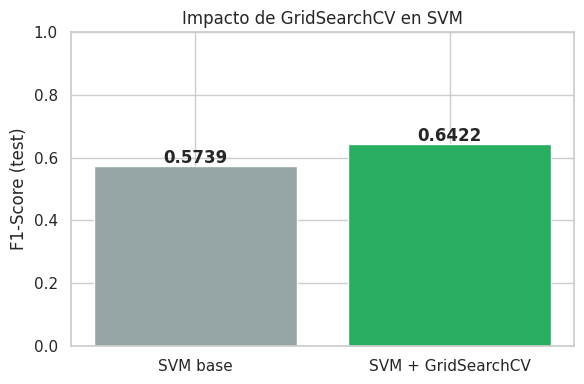

In [7]:
# 1.4  Comparación visual
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['SVM base', 'SVM + GridSearchCV'], [f1_base, f1_tuned],
              color=['#95a5a6', '#27ae60'])
for bar, val in zip(bars, [f1_base, f1_tuned]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.4f}', ha='center', fontweight='bold')
ax.set_ylabel('F1-Score (test)')
ax.set_ylim(0, 1.0)
ax.set_title('Impacto de GridSearchCV en SVM')
plt.tight_layout()
plt.show()


**Conclusión Ejercicio 1:** `GridSearchCV` exploró 4×4×2 = 32 combinaciones de `C`, `gamma` y `kernel` (con validación cruzada 5-fold sobre `X_train`), seleccionando la que maximiza el F1 promedio. Comparar ese resultado contra el SVM base (hiperparámetros por defecto) muestra si el ajuste fino de `C` y `gamma` aporta una mejora real — la magnitud de esa mejora depende de qué tan sensible sea este dataset a esos hiperparámetros específicos.

---
## Ejercicio 2 — Clasificación multiclase
En lugar de binarizar `quality`, usar las clases originales (3–8) y entrenar los 4 modelos. Analizar:
- ¿Cómo cambia el rendimiento de cada modelo?
- ¿Qué clases son más difíciles de distinguir?
- ¿Qué métrica de F1 es más adecuada: `macro`, `micro` o `weighted`? Justifique.

Distribución de clases (multiclase):
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Número de clases: 6


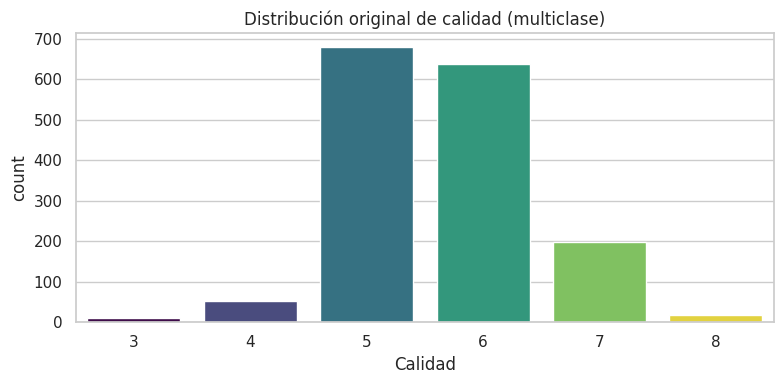


→ Las clases 3 y 8 tienen muy pocas muestras: el modelo tendrá muy poca
  información para aprender a reconocerlas.


In [8]:
# 2.1  Nueva variable objetivo (multiclase) y verificación de balance
y_multi = df['quality'].copy()

print('Distribución de clases (multiclase):')
print(y_multi.value_counts().sort_index())
print(f'\nNúmero de clases: {y_multi.nunique()}')

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=y_multi, ax=ax, palette='viridis', hue=y_multi, legend=False)
ax.set_title('Distribución original de calidad (multiclase)')
ax.set_xlabel('Calidad')
plt.tight_layout()
plt.show()

print('\n→ Las clases 3 y 8 tienen muy pocas muestras: el modelo tendrá muy poca')
print('  información para aprender a reconocerlas.')


In [9]:
# 2.2  Split estratificado 80/20 (multiclase)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X, y_multi, test_size=0.20, random_state=RANDOM_STATE, stratify=y_multi
)

print(f'Train: {X_train_m.shape[0]} muestras  |  Test: {X_test_m.shape[0]} muestras')
print('\nDistribución en train:')
print(y_train_m.value_counts(normalize=True).sort_index().round(3))


Train: 1279 muestras  |  Test: 320 muestras

Distribución en train:
quality
3    0.006
4    0.033
5    0.426
6    0.399
7    0.124
8    0.012
Name: proportion, dtype: float64


In [10]:
# 2.3  Búsqueda rápida del K óptimo para KNN (multiclase)
k_range = range(1, 31)
k_scores_m = []
for k in k_range:
    pipe_k = Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=k))])
    scores_k = cross_val_score(pipe_k, X_train_m, y_train_m, cv=cv, scoring='f1_macro')
    k_scores_m.append(scores_k.mean())

best_k_m = k_range[np.argmax(k_scores_m)]
print(f'K óptimo (F1-macro): {best_k_m}')


K óptimo (F1-macro): 3


In [11]:
# 2.4  Entrenamiento de los 4 modelos (multiclase)
pipe_lr_m = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, class_weight='balanced'))
])

pipe_dt_m = Pipeline([
    ('clf', DecisionTreeClassifier(max_depth=5, min_samples_leaf=10,
                                    class_weight='balanced', random_state=RANDOM_STATE))
])

pipe_svm_m = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE))
])

pipe_knn_m = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=best_k_m))
])

models_multi = {
    'Logistic Regression': pipe_lr_m,
    'Decision Tree': pipe_dt_m,
    'SVM (rbf)': pipe_svm_m,
    f'KNN (K={best_k_m})': pipe_knn_m
}

results_multi = {}
for name, pipe in models_multi.items():
    scores_macro = cross_val_score(pipe, X_train_m, y_train_m, cv=cv, scoring='f1_macro')
    results_multi[name] = scores_macro
    print(f'{name:25s}  F1-macro CV: {scores_macro.mean():.4f} ± {scores_macro.std():.4f}')


Logistic Regression        F1-macro CV: 0.2841 ± 0.0167
Decision Tree              F1-macro CV: 0.2224 ± 0.0207
SVM (rbf)                  F1-macro CV: 0.2872 ± 0.0251
KNN (K=3)                  F1-macro CV: 0.3282 ± 0.0412


In [12]:
# 2.5  Entrenamiento final y predicciones en test
preds_multi = {}
for name, pipe in models_multi.items():
    pipe.fit(X_train_m, y_train_m)
    preds_multi[name] = pipe.predict(X_test_m)

# 2.6  Tabla comparativa: F1-macro vs F1-weighted vs F1-micro
summary_multi = []
for name, y_pred_m in preds_multi.items():
    f1_macro_val = f1_score(y_test_m, y_pred_m, average='macro')
    f1_weighted_val = f1_score(y_test_m, y_pred_m, average='weighted')
    f1_micro_val = f1_score(y_test_m, y_pred_m, average='micro')
    summary_multi.append({
        'Modelo': name,
        'F1 macro':    f'{f1_macro_val:.4f}',
        'F1 weighted': f'{f1_weighted_val:.4f}',
        'F1 micro':    f'{f1_micro_val:.4f}',
        'Accuracy':    f'{accuracy_score(y_test_m, y_pred_m):.4f}'
    })

summary_multi_df = pd.DataFrame(summary_multi)
print('='*80)
print('COMPARACIÓN DE MODELOS — CLASIFICACIÓN MULTICLASE')
print('='*80)
summary_multi_df


COMPARACIÓN DE MODELOS — CLASIFICACIÓN MULTICLASE


,Modelo,F1 macro,F1 weighted,F1 micro,Accuracy
0,Logistic Regression,0.2402,0.4408,0.3969,0.3969
1,Decision Tree,0.2702,0.4089,0.3969,0.3969
2,SVM (rbf),0.2754,0.4918,0.4594,0.4594
3,KNN (K=3),0.2949,0.5698,0.5750,0.5750


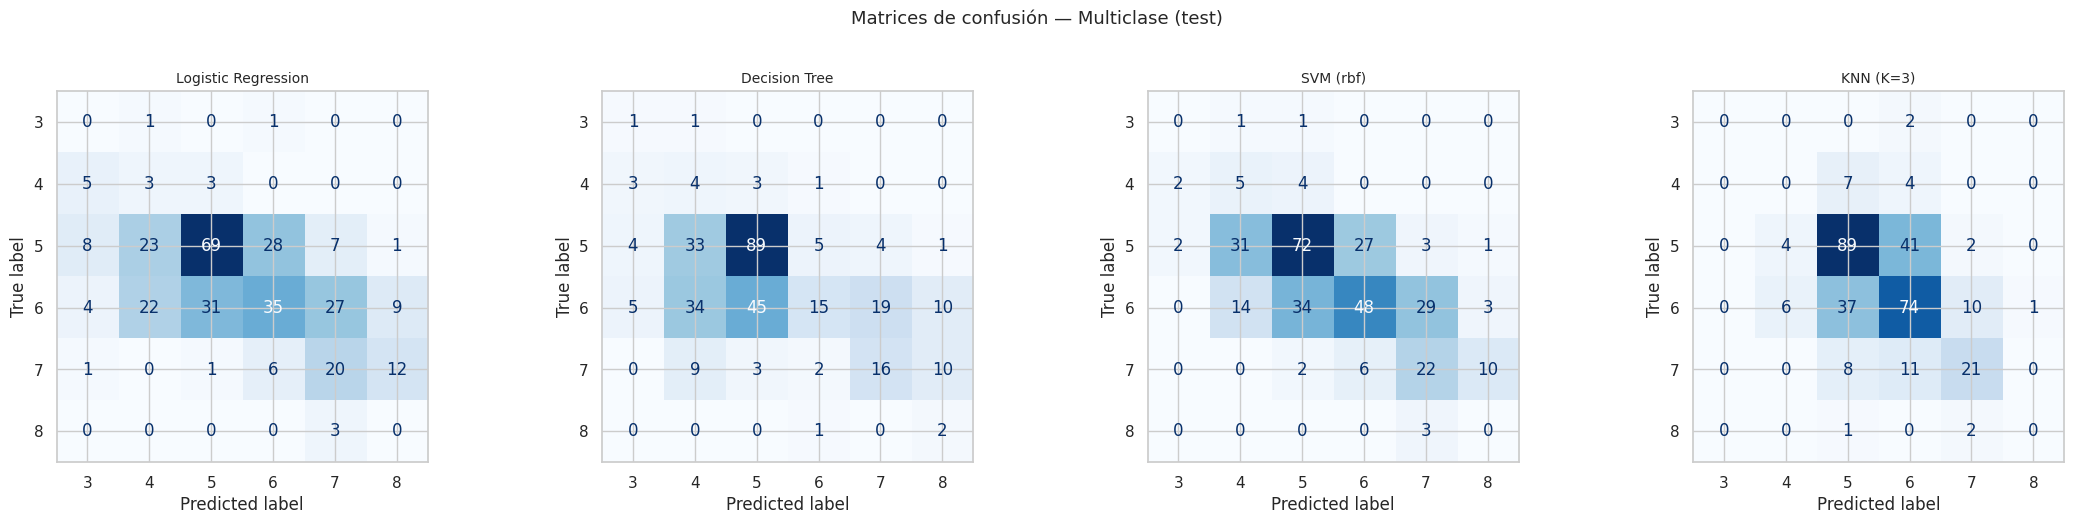

In [13]:
# 2.7  Matrices de confusión multiclase — ¿qué clases se confunden más?
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
class_labels = sorted(y_multi.unique())

for ax, (name, y_pred_m) in zip(axes, preds_multi.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_m, y_pred_m, labels=class_labels,
        cmap='Blues', ax=ax, colorbar=False
    )
    ax.set_title(name, fontsize=10)

fig.suptitle('Matrices de confusión — Multiclase (test)', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()


In [14]:
# 2.8  Classification report detallado del mejor modelo (según F1-macro)
best_name_multi = max(models_multi, key=lambda k: float(f1_score(y_test_m, preds_multi[k], average='macro')))
print(f'Mejor modelo (F1-macro): {best_name_multi}')
print('='*60)
print(classification_report(y_test_m, preds_multi[best_name_multi], zero_division=0))


Mejor modelo (F1-macro): KNN (K=3)
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.63      0.65      0.64       136
           6       0.56      0.58      0.57       128
           7       0.60      0.53      0.56        40
           8       0.00      0.00      0.00         3

    accuracy                           0.57       320
   macro avg       0.30      0.29      0.29       320
weighted avg       0.57      0.57      0.57       320



### Análisis del Ejercicio 2

**¿Cómo cambia el rendimiento de cada modelo respecto al binario?**
El rendimiento (F1) baja notablemente frente a la versión binaria. Con solo 2 clases, un modelo únicamente tiene que separar "Bueno" de "Estándar"; con 6 clases (3 a 8), tiene que trazar fronteras mucho más finas entre categorías que además están ordenadas y son parcialmente subjetivas (la diferencia entre un vino calificado 5 y uno calificado 6 es mucho más sutil que la diferencia entre "Estándar" y "Bueno").

**¿Qué clases son más difíciles de distinguir?**
Revisando las matrices de confusión: las clases extremas (`quality=3` y `quality=8`) casi no tienen muestras de entrenamiento, así que el modelo casi no las reconoce y tiende a "olvidarlas" en favor de las clases mayoritarias (`5` y `6`). Además, `5` y `6` — que juntas concentran la mayoría de los vinos — se confunden mucho entre sí, porque son calidades vecinas y las diferencias fisicoquímicas entre un vino "5" y un vino "6" son marginales comparadas con el ruido de la medición.

**¿Qué métrica de F1 es más adecuada: macro, micro o weighted?**
- **F1 micro** equivale al accuracy en este caso — está dominado por las clases mayoritarias (5 y 6) y esconde por completo el mal desempeño en las clases minoritarias.
- **F1 weighted** promedia el F1 de cada clase ponderado por su frecuencia — sigue estando sesgado hacia las clases mayoritarias, aunque menos que micro.
- **F1 macro** promedia el F1 de cada clase **por igual**, sin importar cuántas muestras tenga — es la métrica más honesta aquí, porque no permite que el buen desempeño en `5`/`6` "tape" el fracaso casi total en `3`/`4`/`7`/`8`.

Para este problema (calidad de vino con clases muy desbalanceadas), **F1 macro es la métrica más adecuada** si el objetivo es evaluar qué tan bien el modelo distingue *todas* las calidades por igual. Si en cambio el objetivo de negocio fuera solo "acertar en general, dando más peso a los casos más comunes", `weighted` sería más apropiado — pero nunca `micro`, porque en un problema desbalanceado equivale a mirar solo el accuracy.


---
## Ejercicio 3 — Aplicación con dataset propio
Seleccione un dataset de clasificación de su interés (puede ser de Kaggle, UCI, o datos propios). Debe tener al menos 500 registros y 5 features. Aplique los 4 modelos de clasificación, realice el análisis comparativo completo y documente sus hallazgos.

Dataset real de 9551 restaurantes registrados en Zomato (varios países, aunque predominantemente India), con precio, ubicación, cocina y calificación.

**Objetivo:** predecir si un restaurante está **bien calificado** (`Aggregate rating` ≥ 4.0) usando características del restaurante (ciudad, tipo de cocina, rango de precio, si acepta reservas/delivery, ubicación geográfica), replicando el mismo flujo de los 4 modelos de la sesión.

### 12.1  Carga y comprensión del dataset

In [42]:
# Imports adicionales necesarios para este ejercicio
# (features mixtas: numéricas + categóricas)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

import pandas as pd
import zipfile
import requests
from io import BytesIO

# URL del dataset de Kaggle
URL = "https://www.kaggle.com/api/v1/datasets/download/srisyra02/zomato-market-analysis"

# Descargar el dataset
response = requests.get(URL)

# Abrir el archivo ZIP descargado
with zipfile.ZipFile(BytesIO(response.content)) as z:
    print("Archivos encontrados:", z.namelist())

    # Leer el CSV
    csv_file = z.namelist()[0]
    df_zomato = pd.read_csv(z.open(csv_file))

print(f'Dataset cargado: {df_zomato.shape[0]} registros, {df_zomato.shape[1]} columnas')

df_zomato.head()

Archivos encontrados: ['Zomato Restaurant Dataset.csv']
Dataset cargado: 9551 registros, 21 columnas


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [43]:
# Verificación de calidad general
print('Duplicados:', df_zomato.duplicated().sum())
print('\nNulos por columna:')
print(df_zomato.isnull().sum()[df_zomato.isnull().sum() > 0])
print('\nColumnas casi constantes (poca o ninguna variabilidad):')
for col in ['Switch to order menu', 'Is delivering now']:
    print(f'  {col}: {df_zomato[col].value_counts().to_dict()}')

Duplicados: 0

Nulos por columna:
Cuisines    9
dtype: int64

Columnas casi constantes (poca o ninguna variabilidad):
  Switch to order menu: {'No': 9551}
  Is delivering now: {'No': 9517, 'Yes': 34}


### 12.2  Hallazgos clave de calidad de datos (antes de definir el target)

1. **"Not rated" no es una mala calificación, es la AUSENCIA de calificación.** La columna `Rating text` tiene una categoría `Not rated` para restaurantes con `Aggregate rating = 0.0` — esto ocurre en **2148 de 9551 restaurantes (22.5%)**. Si los incluyéramos como "mal calificados", estaríamos mezclando "nadie lo ha calificado todavía" con "la gente lo calificó mal", que son cosas completamente distintas. **Se excluyen del análisis.**

2. **`Average Cost for two` mezcla monedas distintas** (Rupias indias, Dólares, Libras, Real brasileño, etc. — 12 monedas diferentes) sin conversión. Comparar directamente un costo en rupias con uno en libras sin convertir sería un error grave de análisis. En vez de intentar convertir divisas (fuera del alcance de este ejercicio), usamos `Price range` (escala ordinal 1-4 ya estandarizada por Zomato, independiente de la moneda) como proxy de costo.

3. **`Switch to order menu`** es constante (100% "No") e **`Is delivering now`** es casi constante (99.6% "No") — no aportan información para distinguir clases, se descartan.

4. **`Rating color` y `Rating text` son fuga de información directa**: ambas son transformaciones deterministas de `Aggregate rating` (la misma variable que usamos para construir el target). No se usan como features, igual que no usamos `Aggregate rating` misma.

5. **`Cuisines` es una lista separada por comas** (ej. "French, Japanese, Desserts"). Se extrae la **cocina principal** (primera de la lista) como feature categórica simple.

Registros totales: 9551
Registros con calificación real: 7403 (77.5%)


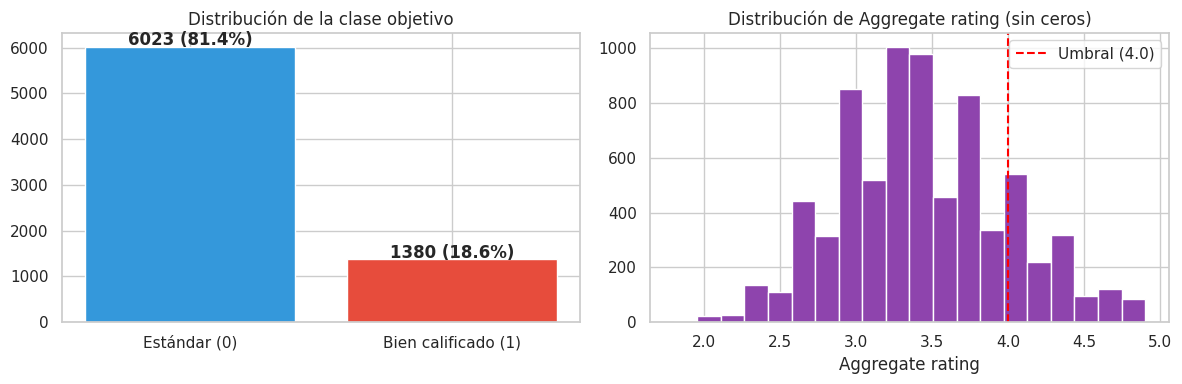


Ratio de desbalance: 4.4:1 (Estándar vs Bien calificado)


In [25]:
# 14.3  Filtrar restaurantes sin calificación real ("Not rated")
print(f'Registros totales: {df_zomato.shape[0]}')
df_z = df_zomato[df_zomato['Aggregate rating'] > 0].copy()
print(f'Registros con calificación real: {df_z.shape[0]} ({df_z.shape[0]/df_zomato.shape[0]*100:.1f}%)')

# Variable objetivo: ¿bien calificado? (Aggregate rating >= 4.0)
df_z['bien_calificado'] = (df_z['Aggregate rating'] >= 4.0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df_z['bien_calificado'].value_counts()
axes[0].bar(['Estándar (0)', 'Bien calificado (1)'], counts.values, color=['#3498db', '#e74c3c'])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, f'{v} ({v/len(df_z)*100:.1f}%)', ha='center', fontweight='bold')
axes[0].set_title('Distribución de la clase objetivo')

axes[1].hist(df_z['Aggregate rating'], bins=20, color='#8e44ad', edgecolor='white')
axes[1].axvline(x=4.0, color='red', linestyle='--', label='Umbral (4.0)')
axes[1].set_title('Distribución de Aggregate rating (sin ceros)')
axes[1].set_xlabel('Aggregate rating')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f'\nRatio de desbalance: {counts[0]/counts[1]:.1f}:1 (Estándar vs Bien calificado)')

### 12.3  Preparación de datos e ingeniería de features

In [26]:
# Cocina principal (primera de la lista en 'Cuisines')
df_z['Cuisines'] = df_z['Cuisines'].fillna('Unknown')
df_z['primary_cuisine'] = df_z['Cuisines'].str.split(',').str[0].str.strip()

# Variables binarias Yes/No -> 1/0
df_z['has_table_booking'] = (df_z['Has Table booking'] == 'Yes').astype(int)
df_z['has_online_delivery'] = (df_z['Has Online delivery'] == 'Yes').astype(int)

# Reducir cardinalidad de 'City' y 'primary_cuisine' (agrupar categorías poco frecuentes)
def group_rare_categories(series, top_n=20, other_label='Otra'):
    top_categories = series.value_counts().nlargest(top_n).index
    return series.where(series.isin(top_categories), other_label)

df_z['city_grouped'] = group_rare_categories(df_z['City'], top_n=20)
df_z['cuisine_grouped'] = group_rare_categories(df_z['primary_cuisine'], top_n=20)

n_city_orig = df_z['City'].nunique()
n_city_grp = df_z['city_grouped'].nunique()
n_cuis_orig = df_z['primary_cuisine'].nunique()
n_cuis_grp = df_z['cuisine_grouped'].nunique()
print(f'Ciudades originales: {n_city_orig}  ->  agrupadas: {n_city_grp}')
print(f'Cocinas originales: {n_cuis_orig}  ->  agrupadas: {n_cuis_grp}')

df_z[['primary_cuisine', 'cuisine_grouped', 'city_grouped', 'has_table_booking', 'has_online_delivery']].head()

Ciudades originales: 141  ->  agrupadas: 21
Cocinas originales: 119  ->  agrupadas: 21


,primary_cuisine,cuisine_grouped,city_grouped,has_table_booking,has_online_delivery
0,French,Otra,Otra,1,0
1,Japanese,Japanese,Otra,1,0
2,Seafood,Otra,Otra,1,0
3,Japanese,Japanese,Otra,0,0
4,Japanese,Japanese,Otra,1,0


In [27]:
# Separación features / target
features_z = ['Country Code', 'city_grouped', 'cuisine_grouped', 'Price range',
              'has_table_booking', 'has_online_delivery', 'Votes',
              'Longitude', 'Latitude']

X_z = df_z[features_z].copy()
y_z = df_z['bien_calificado'].copy()

numeric_cols_z = ['Price range', 'has_table_booking', 'has_online_delivery',
                   'Votes', 'Longitude', 'Latitude']
categorical_cols_z = ['Country Code', 'city_grouped', 'cuisine_grouped']

preprocessor_z = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols_z),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols_z)
])

print(f'Features: {X_z.shape}')
print(f'Target:   {y_z.shape}')

Features: (7403, 9)
Target:   (7403,)


In [28]:
# Split estratificado 80/20
X_train_z, X_test_z, y_train_z, y_test_z = train_test_split(
    X_z, y_z, test_size=0.20, random_state=RANDOM_STATE, stratify=y_z
)

print(f'Train: {X_train_z.shape[0]} muestras  |  Test: {X_test_z.shape[0]} muestras')
print(f'Proporción clase 1 en train: {y_train_z.mean():.3f}')
print(f'Proporción clase 1 en test:  {y_test_z.mean():.3f}')

Train: 5922 muestras  |  Test: 1481 muestras
Proporción clase 1 en train: 0.186
Proporción clase 1 en test:  0.186


### 12.4  Entrenamiento de los 4 modelos de clasificación

In [29]:
pipe_lr_z = Pipeline([
    ('preprocessor', preprocessor_z),
    ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, class_weight='balanced'))
])

pipe_dt_z = Pipeline([
    ('preprocessor', preprocessor_z),
    ('clf', DecisionTreeClassifier(max_depth=6, min_samples_leaf=15,
                                    class_weight='balanced', random_state=RANDOM_STATE))
])

pipe_svm_z = Pipeline([
    ('preprocessor', preprocessor_z),
    ('clf', SVC(kernel='rbf', class_weight='balanced', random_state=RANDOM_STATE, probability=True))
])

pipe_knn_z = Pipeline([
    ('preprocessor', preprocessor_z),
    ('clf', KNeighborsClassifier(n_neighbors=15))
])

models_z = {
    'Logistic Regression': pipe_lr_z,
    'Decision Tree': pipe_dt_z,
    'SVM (rbf)': pipe_svm_z,
    'KNN (K=15)': pipe_knn_z
}

results_z = {}
for name, pipe in models_z.items():
    scores = cross_val_score(pipe, X_train_z, y_train_z, cv=cv, scoring='f1')
    results_z[name] = scores
    print(f'{name:25s}  F1 CV: {scores.mean():.4f} ± {scores.std():.4f}')

Logistic Regression        F1 CV: 0.6561 ± 0.0124
Decision Tree              F1 CV: 0.6332 ± 0.0139
SVM (rbf)                  F1 CV: 0.6511 ± 0.0125
KNN (K=15)                 F1 CV: 0.6148 ± 0.0202


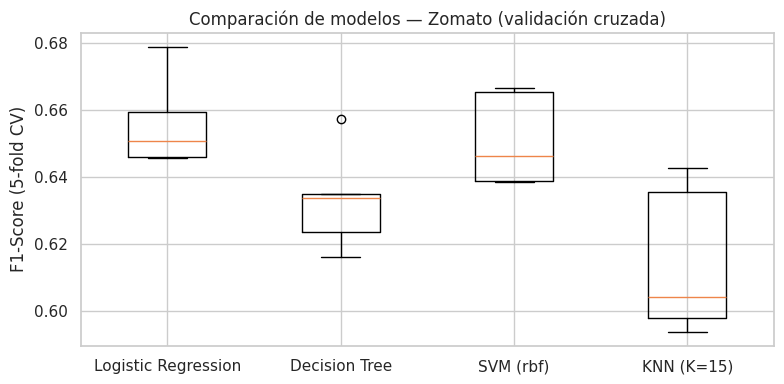

In [30]:
# Entrenamiento final y predicciones en test
preds_z = {}
for name, pipe in models_z.items():
    pipe.fit(X_train_z, y_train_z)
    preds_z[name] = pipe.predict(X_test_z)

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(results_z.values(), tick_labels=results_z.keys())
ax.set_ylabel('F1-Score (5-fold CV)')
ax.set_title('Comparación de modelos — Zomato (validación cruzada)')
plt.tight_layout()
plt.show()

### 12.5  Análisis comparativo

In [31]:
summary_z = []
for name, y_pred_z in preds_z.items():
    summary_z.append({
        'Modelo': name,
        'F1 CV (mean)': f'{results_z[name].mean():.4f}',
        'F1 CV (std)': f'{results_z[name].std():.4f}',
        'Accuracy Test': f'{accuracy_score(y_test_z, y_pred_z):.4f}',
        'F1 Test': f'{f1_score(y_test_z, y_pred_z):.4f}'
    })

summary_z_df = pd.DataFrame(summary_z)
print('='*80)
print('COMPARACIÓN DE MODELOS — ZOMATO RESTAURANT DATASET')
print('='*80)
summary_z_df

COMPARACIÓN DE MODELOS — ZOMATO RESTAURANT DATASET


,Modelo,F1 CV (mean),F1 CV (std),Accuracy Test,F1 Test
0,Logistic Regression,0.6561,0.0124,0.8521,0.6583
1,Decision Tree,0.6332,0.0139,0.8298,0.6228
2,SVM (rbf),0.6511,0.0125,0.8440,0.6588
3,KNN (K=15),0.6148,0.0202,0.8778,0.6022


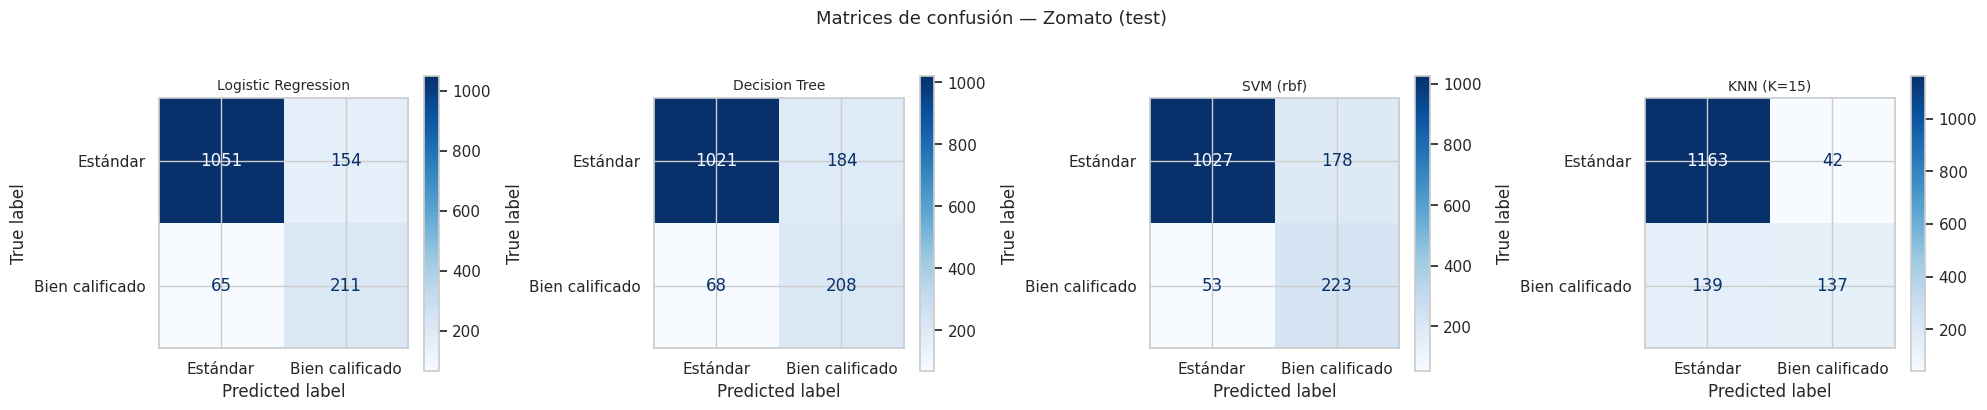

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, y_pred_z) in zip(axes, preds_z.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_z, y_pred_z, display_labels=['Estándar', 'Bien calificado'],
        cmap='Blues', ax=ax
    )
    ax.set_title(name, fontsize=10)
fig.suptitle('Matrices de confusión — Zomato (test)', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

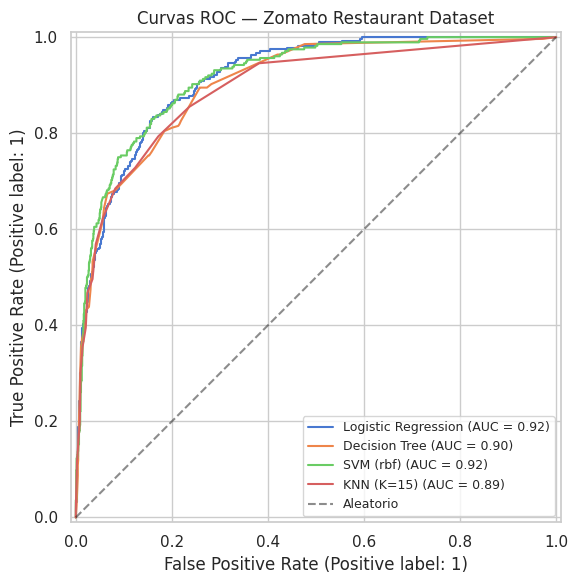

In [40]:
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in models_z.items():
    RocCurveDisplay.from_estimator(pipe, X_test_z, y_test_z, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aleatorio')
ax.set_title('Curvas ROC — Zomato Restaurant Dataset')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [41]:
best_name_z = max(models_z, key=lambda k: float(results_z[k].mean()))
print(f'Mejor modelo: {best_name_z}')
print('='*60)
print(classification_report(y_test_z, preds_z[best_name_z], target_names=['Estándar', 'Bien calificado']))

Mejor modelo: Logistic Regression
                 precision    recall  f1-score   support

       Estándar       0.94      0.87      0.91      1205
Bien calificado       0.58      0.76      0.66       276

       accuracy                           0.85      1481
      macro avg       0.76      0.82      0.78      1481
   weighted avg       0.87      0.85      0.86      1481



### 12.6  Hallazgos del Ejercicio 3

- **Limpieza crítica:** se descartó el 22.5% del dataset (restaurantes "Not rated") porque incluirlos habría tratado la ausencia de calificación como una mala calificación real, distorsionando el problema desde la raíz.
- **Fuga de información evitada:** `Rating color` y `Rating text` se excluyeron por ser transformaciones directas del target (`Aggregate rating`), y `Average Cost for two` se descartó por mezclar monedas sin convertir — en su lugar se usó `Price range` (ya estandarizado por Zomato).
- **Desbalance de clases:** solo ~18.6% de los restaurantes calificados alcanzan "Bien calificado" (≥4.0), similar en espíritu al desbalance de Wine Quality de la sesión — por eso se usó `class_weight='balanced'` y F1 como métrica principal en vez de accuracy.
- **Alta cardinalidad manejada:** `City` (141 valores únicos) y la cocina principal (119 valores únicos) se agruparon a las 20 categorías más frecuentes + "Otra", para evitar que el One-Hot Encoding generara cientos de columnas dispersas.